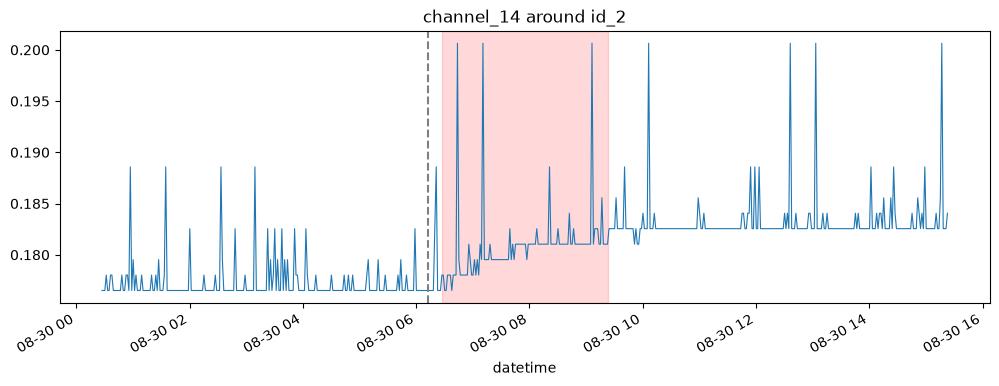

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = 'ESA-Mission1'
ANOMALY_ID, CHANNEL = 'id_2', 'channel_14'

labels = pd.read_csv(f'{DATA_DIR}/labels.csv', parse_dates=['StartTime', 'EndTime'])
row = labels[(labels.ID == ANOMALY_ID) & (labels.Channel == CHANNEL)].iloc[0]
start, end = row.StartTime.tz_localize(None), row.EndTime.tz_localize(None)

telemetry = pd.read_pickle(f'{DATA_DIR}/channels/{CHANNEL}.zip')
window = telemetry.loc[start - pd.Timedelta(hours=6) : end + pd.Timedelta(hours=6)]

ax = window.plot(figsize=(12, 4), lw=0.8, legend=False, title=f'{CHANNEL} around {ANOMALY_ID}')
ax.axvspan(start, end, color='red', alpha=0.15)
ax.axvline(start - pd.Timedelta(minutes=15), color='gray', ls='--')
plt.show()